In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [35]:
os.makedirs("charts",exist_ok=True)

In [36]:
subscribers = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\subscribers_clean.csv", parse_dates=["signup_date", "churn_date"])
titles      = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\titles_clean.csv",      parse_dates=["date_added", "license_expiry"])
watch       = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\watch_history_clean.csv", parse_dates=["watch_date"])
reviews     = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\reviews_clean.csv",     parse_dates=["review_date"])

In [37]:
print(watch.shape, watch["watch_date"].isna().sum())

(650000, 11) 0


In [38]:
sessions = watch.merge(titles[["title_id", "type", "primary_genre", "country", "is_original"]], on="title_id", how="left")
print(sessions.shape) 

(650000, 15)


# Chart 1:	Monthly viewing volume 

##monthly sessions (busiest months highlighted)

109
month
2026-05    224696
2026-04     90383
2026-03     55665
2026-02     33795
2026-01     27970
Freq: M, dtype: int64


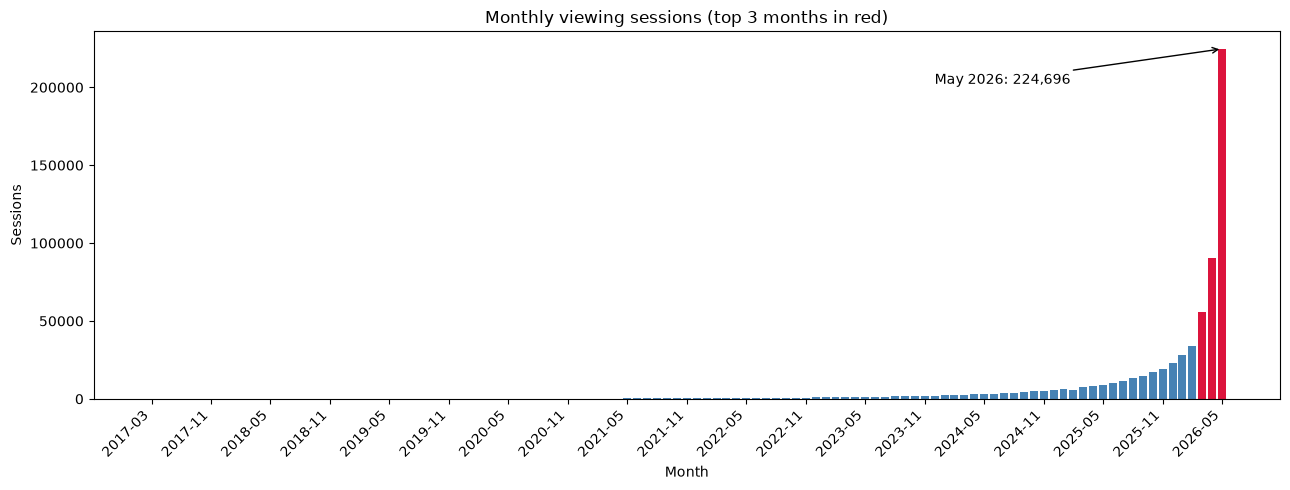

In [39]:
sessions["month"] = sessions["watch_date"].dt.to_period("M")
monthly = sessions.groupby("month").size()
print(len(monthly))       
print(monthly.sort_values(ascending=False).head(5))   

top3 = monthly.nlargest(3).index
colors = ["crimson" if m in top3 else "steelblue" for m in monthly.index]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(monthly.index.astype(str), monthly.values, color=colors)
ax.annotate("May 2026: 224,696", xy=(len(monthly) - 1, monthly.iloc[-1]),
            xytext=(len(monthly) - 30, monthly.iloc[-1] * 0.9),
            arrowprops=dict(arrowstyle="->"))
ax.set_xticks(range(0, len(monthly), 6))
ax.set_xticklabels(monthly.index.astype(str)[::6], rotation=45, ha="right")
ax.set_title("Monthly viewing sessions (top 3 months in red)")
ax.set_xlabel("Month"); ax.set_ylabel("Sessions")
plt.tight_layout()
plt.savefig("charts/01_monthly_sessions.png", dpi=150)
plt.show()

# Supplementary: log scale, to show that growth was steady before 2026

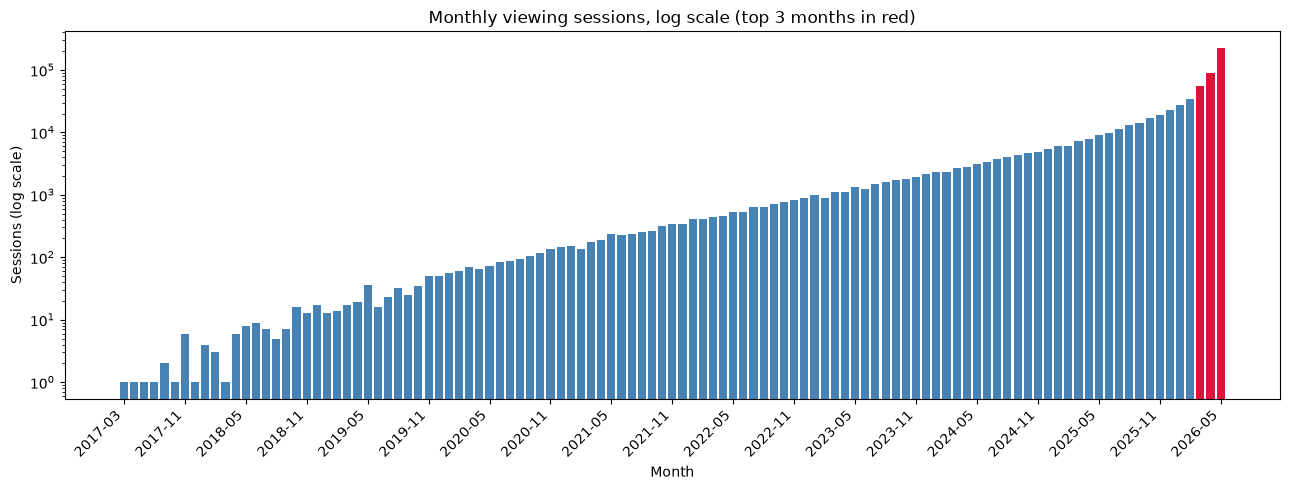

In [40]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(monthly.index.astype(str), monthly.values, color=colors, edgecolor="none")
ax.set_yscale("log")
ax.set_xticks(range(0, len(monthly), 6))
ax.set_xticklabels(monthly.index.astype(str)[::6], rotation=45, ha="right")
ax.set_title("Monthly viewing sessions, log scale (top 3 months in red)")
ax.set_xlabel("Month"); ax.set_ylabel("Sessions (log scale)")
plt.tight_layout()
plt.savefig("charts/01b_monthly_sessions_log.png", dpi=150)
plt.show()

**Observation: Monthly viewing volume**

Viewing sessions have grown steadily across the 109 months in the data, from a handful per month in 2017 to 224,696 in May 2026. The three busiest months are the three most recent (May: 224,696, April: 90,383, March: 55,665), which together hold 57% of all 650,000 sessions, and May alone is about 2.5 times April. On the log-scale version, the bars rise in a near-straight line from 2018 onward, so this is sustained growth and not a one-off spike, with the last few months sitting slightly above the trend. Because volume rises every month, the "busiest" months mainly mark the latest months and not a seasonal peak.

# Chart 2:	Monthly watch hours trend 

year     2023     2024      2025       2026
mon                                        
1      5232.0  11494.0   31264.0   143522.0
2      4557.0  11743.0   29352.0   174565.0
3      6126.0  14087.0   36106.0   286088.0
4      5263.0  14666.0   41128.0   463337.0
5      6869.0  17029.0   46933.0  1157786.0
6      6357.0  17264.0   50131.0        NaN
7      7378.0  19355.0   58683.0        NaN
8      8489.0  19915.0   66709.0        NaN
9      9069.0  22455.0   71767.0        NaN
10     9743.0  24255.0   85269.0        NaN
11     9464.0  24269.0   98566.0        NaN
12    11118.0  27462.0  118031.0        NaN


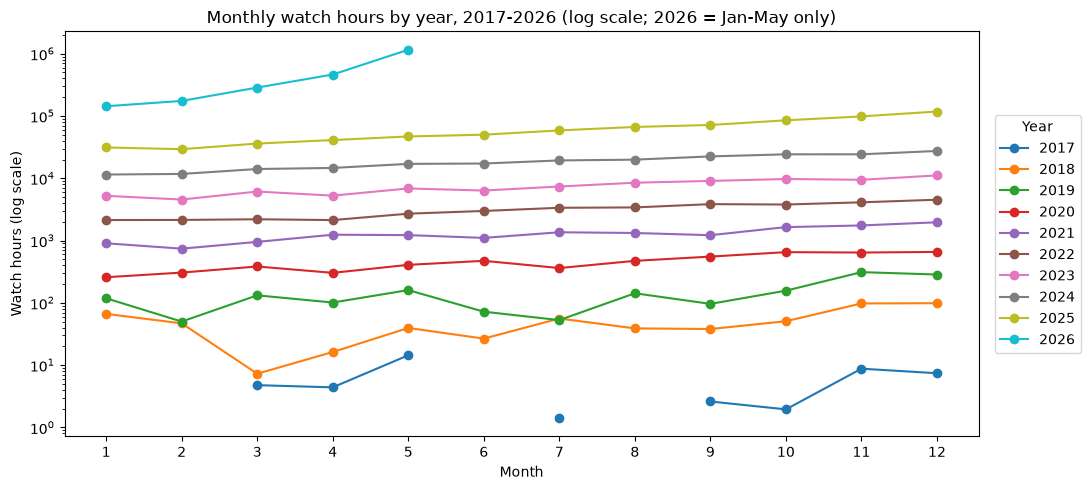

In [41]:
sessions["hours"] = sessions["watch_duration_min"] / 60
sessions["year"]  = sessions["watch_date"].dt.year
sessions["mon"]   = sessions["watch_date"].dt.month

yoy = sessions.pivot_table(index="mon", columns="year", values="hours", aggfunc="sum")
print(yoy[[2023, 2024, 2025, 2026]].round(0))        # May: 2025 = 46,933 and 2026 = 1,157,786

fig, ax = plt.subplots(figsize=(11, 5))
for y in range(2017, 2027):
    ax.plot(yoy.index, yoy[y], marker="o", label=str(y))
ax.set_yscale("log")
ax.set_xticks(range(1, 13))
ax.set_title("Monthly watch hours by year, 2017-2026 (log scale; 2026 = Jan-May only)")
ax.set_xlabel("Month"); ax.set_ylabel("Watch hours (log scale)")
ax.legend(title="Year", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig("charts/02_monthly_hours_yoy.png", dpi=150,bbox_inches="tight")
plt.show()

### Sensitivity check: does the growth trend hold without the after_churn sessions?

In [42]:
print("All sessions, watch hours by year:")
print(sessions.groupby("year")["hours"].sum().loc[[2024, 2025, 2026]].round(0))
print("\nExcluding sessions dated after churn:")
print(sessions[~sessions["after_churn"]].groupby("year")["hours"].sum().loc[[2024, 2025, 2026]].round(0))

All sessions, watch hours by year:
year
2024     223994.0
2025     733939.0
2026    2225299.0
Name: hours, dtype: float64

Excluding sessions dated after churn:
year
2024     190010.0
2025     607033.0
2026    1731101.0
Name: hours, dtype: float64


**Observation: Monthly watch hours, year over year**

Watch hours rise within every year and each year sits well above the one before it: 2025 totalled about 734,000 hours, roughly 3.3 times 2024 (about 224,000), and the five months of 2026 already total about 2.2 million hours, three times all of 2025. Comparing the same months, January-May 2026 has about 12 times the hours of January-May 2025, and May alone is about 25 times higher (1,157,786 vs 46,933). The 2022-2025 lines are almost parallel with no repeated seasonal dip, so growth looks steady, while 2026 is far steeper; the 2017-2018 lines are broken and noisy because those years have only a handful of sessions per month. The pattern holds when sessions dated after a subscriber's churn date are excluded: 2025 is still about 3.2 times 2024, and Jan-May 2026 is about 2.9 times all of 2025. Since 2026 has only five months it can't be compared as a full year, and the log scale is used because the years differ by an order of magnitude.

# Chart 3:	Genre-wise watch-hours share 

primary_genre
Drama          501884.0
Comedy         423149.0
Action         393172.0
Thriller       307025.0
Documentary    291217.0
Name: hours, dtype: float64
primary_genre
Drama          15.1
Comedy         12.7
Action         11.8
Thriller        9.2
Documentary     8.7
Name: hours, dtype: float64
16 3333468


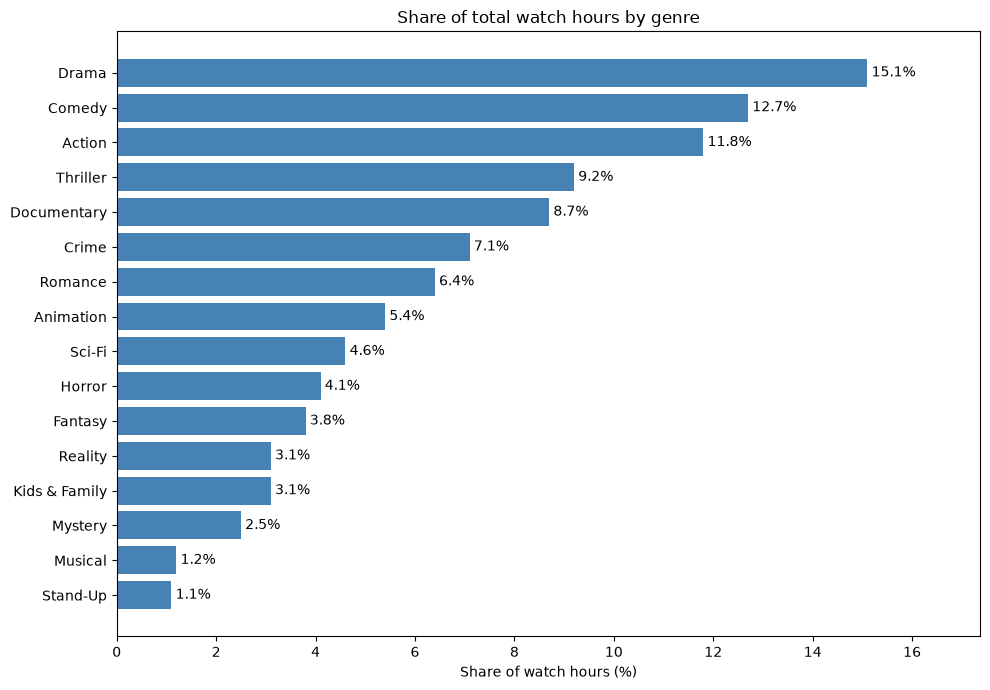

In [43]:
#genre share of watch hours
genre = (sessions.groupby("primary_genre")["hours"].sum()
                 .sort_values(ascending=True))       
share = (genre / genre.sum() * 100).round(1)
print(genre.sort_values(ascending=False).head(5).round(0)) 
print(share.sort_values(ascending=False).head(5))    
print(len(genre), round(genre.sum()))                       

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(genre.index, share, color="steelblue")
ax.bar_label(bars, labels=[f"{v}%" for v in share], padding=3)
ax.set_title("Share of total watch hours by genre")
ax.set_xlabel("Share of watch hours (%)")
ax.set_xlim(0, share.max() * 1.15)
plt.tight_layout()
plt.savefig("charts/03_genre_share.png", dpi=150)
plt.show()

### Share of sessions that are TV shows, by genre

In [44]:
print(sessions.groupby("primary_genre")["type"].apply(lambda s: (s == "TV Show").mean()).round(2).sort_values())

primary_genre
Musical          0.34
Action           0.38
Fantasy          0.38
Horror           0.38
Sci-Fi           0.38
Thriller         0.39
Reality          0.40
Romance          0.40
Drama            0.41
Mystery          0.42
Stand-Up         0.42
Comedy           0.42
Crime            0.43
Documentary      0.44
Animation        0.49
Kids & Family    0.49
Name: type, dtype: float64


#

### Hours per title by genre

In [45]:
per_title = (sessions.groupby("primary_genre")["hours"].sum() /
             titles.groupby("primary_genre")["title_id"].nunique()).sort_values(ascending=False)
print(per_title.round(0).head(5))

primary_genre
Animation        496.0
Kids & Family    437.0
Documentary      400.0
Action           393.0
Crime            387.0
dtype: float64


**Observation: Genre share of watch hours**

Drama earns the most watch time at 15.1% of all hours (about 502,000 of 3.33 million), ahead of Comedy (12.7%) and Action (11.8%); the top three genres hold about 40% of hours and the top five about 57%. The order is almost identical when measured in sessions, and TV shows make up a similar 34-49% of sessions in every genre, so it is not an artefact of long TV sessions. However, Drama's lead mainly reflects catalogue size: it has the most titles (1,393), and per title it earns about 360 hours, below Animation (496), Kids & Family (437), Documentary (400), Action (393) and Crime (387). Total hours therefore show where viewing volume is concentrated, while hours per title point to the genres whose individual titles perform best.

# Chart 4:	Content type split 

type
Movie      13.5
TV Show    86.5
Name: hours, dtype: float64
type
Movie      382330
TV Show    267670
Name: count, dtype: int64


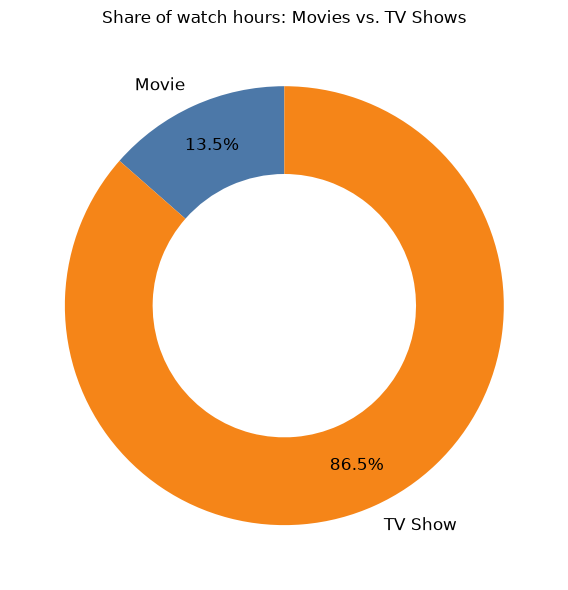

In [46]:
# Movies vs TV Shows
type_hours = sessions.groupby("type")["hours"].sum()
type_share = (type_hours / type_hours.sum() * 100).round(1)
print(type_share)       
print(sessions["type"].value_counts())        

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(type_hours, labels=type_hours.index, autopct="%1.1f%%", startangle=90,
       colors=["#4c78a8", "#f58518"], pctdistance=0.8,
       wedgeprops=dict(width=0.4), textprops=dict(fontsize=12))
ax.set_title("Share of watch hours: Movies vs. TV Shows")
plt.tight_layout()
plt.savefig("charts/04_content_type_split.png", dpi=150)
plt.show()

In [47]:
##hours-vs-sessions
print(sessions.groupby("type")["hours"].mean().round(2))   

type
Movie       1.18
TV Show    10.77
Name: hours, dtype: float64


In [48]:
print(titles.groupby("type")["content_duration_min"].median())  

type
Movie      107.0
TV Show    878.0
Name: content_duration_min, dtype: float64


**Observation: Content type split**

TV Shows account for 86.5% of all watch hours and Movies for only 13.5%. The picture reverses when counting sessions: Movies have 382,330 sessions (59%) against 267,670 for TV Shows (41%). The gap exists because a TV session is far longer, averaging about 10.8 hours against about 1.2 hours for a movie, since a TV title's duration covers all of its seasons. TV Shows therefore dominate watch hours, but this does not mean subscribers watch them more often, and any comparison of the two types should state which measure is used.

# Chart 5:Top 10 countries by watch hours 

country
United States     822685.0
India             464338.0
United Kingdom    282946.0
South Korea       223476.0
Japan             207131.0
Brazil            176354.0
Mexico            157177.0
Spain             143656.0
France            115012.0
Canada            107073.0
Name: hours, dtype: float64


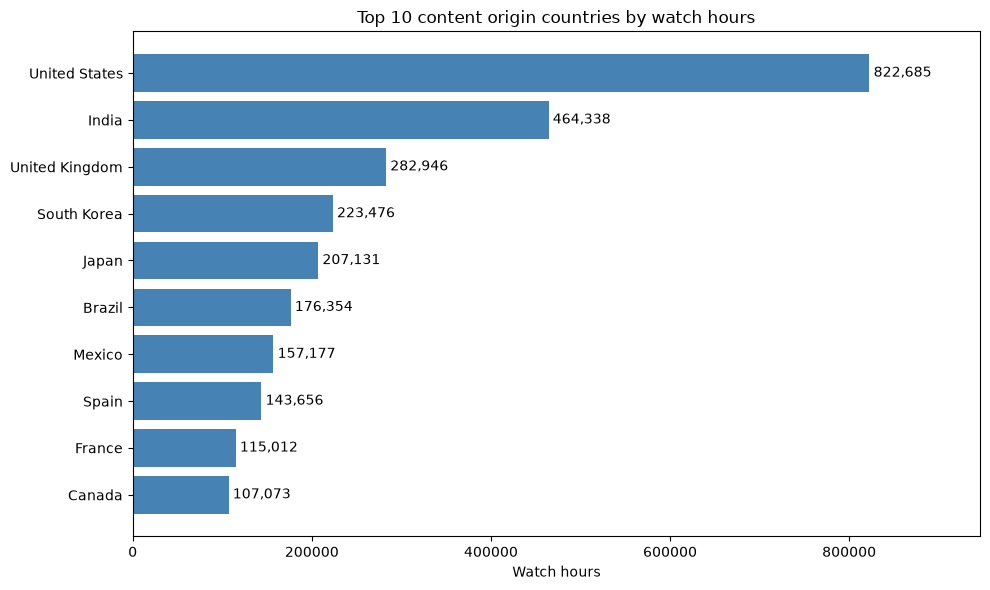

In [49]:
country = (sessions.groupby("country")["hours"].sum().nlargest(10).sort_values())
print(country.sort_values(ascending=False).round(0))   

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(country.index, country.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in country.values], padding=3)
ax.set_title("Top 10 content origin countries by watch hours")
ax.set_xlabel("Watch hours")
ax.set_xlim(0, country.max() * 1.15)
plt.tight_layout()
plt.savefig("charts/05_top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

###  Hours per title by origin country

In [50]:
per_title_c = (sessions.groupby("country")["hours"].sum() /
               titles.groupby("country")["title_id"].nunique()).sort_values(ascending=False)
print(per_title_c.round(0).head(5))

country
Australia    473.0
Indonesia    467.0
Turkey       445.0
Egypt        438.0
Sweden       436.0
dtype: float64


### Top-10 title share and country count

In [51]:
top10 = sessions.groupby("country")["hours"].sum().nlargest(10).index
print(titles["country"].isin(top10).mean().round(3))      
print(titles["country"].nunique())    

0.819
20


**Observation: Top 10 content origin countries**

Content made in the United States earns the most watch time at 822,685 hours (about 25% of the total), followed by India (464,338) and the United Kingdom (282,946). The ranking closely follows catalogue size: the top 10 of the 20 origin countries hold 81% of watch hours and 82% of titles, and per title the US ranks only 11th (363 hours against 473 for Australia, the highest). Hours per title are fairly even across countries, ranging from 294 to 473, so the lead of the largest countries comes mainly from having more content, not from their titles being watched more. The chart groups viewing by where a title was produced, not where the viewer lives.

# Chart 6:	Subscriber plan distribution 

plan_type
Standard          6100
Basic with Ads    4458
Premium           4442
Name: count, dtype: int64
plan_type
Standard          40.7
Basic with Ads    29.7
Premium           29.6
Name: count, dtype: float64
plan_type
Standard          4631
Premium           3639
Basic with Ads    2929
Name: count, dtype: int64


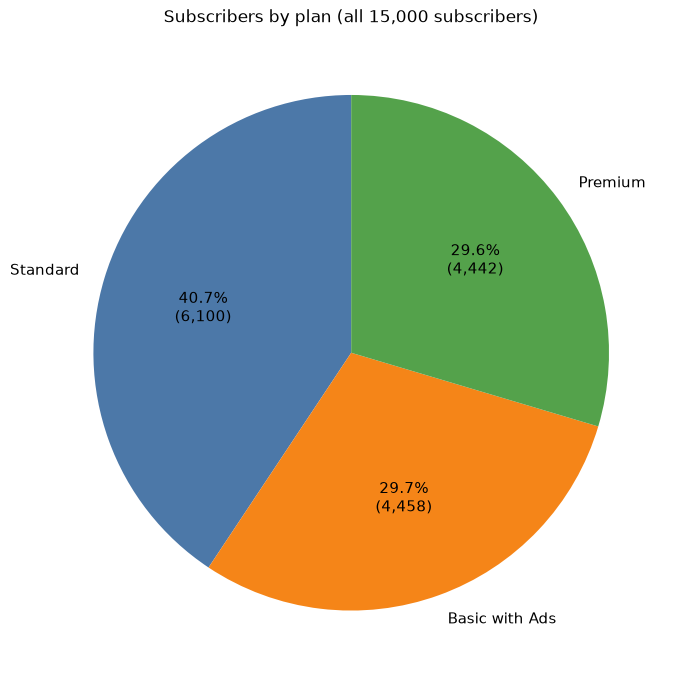

In [52]:
plan = subscribers["plan_type"].value_counts()
print(plan)     
print((plan / plan.sum() * 100).round(1))                  
print(subscribers[subscribers["is_active"]]["plan_type"].value_counts())   # active subscribers only

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(plan.values, labels=plan.index, autopct=lambda p: f"{p:.1f}%\n({p * plan.sum() / 100:,.0f})",
       startangle=90, colors=["#4c78a8", "#f58518", "#54a24b"], textprops=dict(fontsize=11))
ax.set_title("Subscribers by plan (all 15,000 subscribers)")
plt.tight_layout()
plt.savefig("charts/06_plan_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
plan_tbl = pd.DataFrame({"all": subscribers["plan_type"].value_counts(),
                         "active": subscribers[subscribers["is_active"]]["plan_type"].value_counts()})
plan_tbl["churn_rate_pct"] = ((1 - plan_tbl["active"] / plan_tbl["all"]) * 100).round(1)
print(plan_tbl)     

                 all  active  churn_rate_pct
plan_type                                   
Basic with Ads  4458    2929            34.3
Premium         4442    3639            18.1
Standard        6100    4631            24.1


**Observation: Subscriber plan distribution**

Standard is the largest plan with 6,100 subscribers (40.7%), while Basic with Ads (4,458, 29.7%) and Premium (4,442, 29.6%) are almost equal in size. Among the 11,199 active subscribers the mix shifts towards the paid tiers (Standard 41%, Premium 32%, Basic with Ads 26%), because Basic with Ads has the highest churn at about 34%, against 24% for Standard and 18% for Premium. The chart covers all 15,000 subscribers, including those who have left, so it shows who signed up and not who is paying today.

# Chart 7:	Device usage

device
Smart TV           34.1
Mobile             27.0
Laptop             14.8
Tablet             10.0
Game Console        8.0
Streaming Stick     6.0
Name: count, dtype: float64


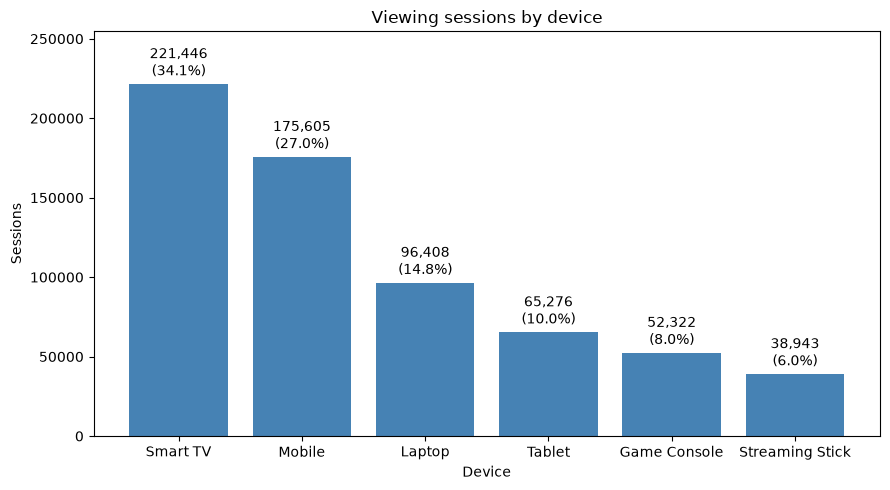

In [54]:
device = sessions["device"].value_counts()
pct = (device / device.sum() * 100).round(1)
print(pct)       
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(device.index, device.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(device.values, pct)], padding=3)
ax.set_title("Viewing sessions by device")
ax.set_xlabel("Device"); ax.set_ylabel("Sessions")
ax.set_ylim(0, device.max() * 1.15)
plt.tight_layout()
plt.savefig("charts/07_device_usage.png", dpi=150, bbox_inches="tight")
plt.show()

In [55]:
m = sessions.merge(subscribers[["subscriber_id", "primary_device"]], on="subscriber_id")
print((m["device"] == m["primary_device"]).mean().round(3))   

0.231


In [56]:
d = sessions.groupby("device")["hours"].agg(["sum", "count", "mean"]).round(2)
d["hours_share_%"] = (d["sum"] / d["sum"].sum() * 100).round(1)
print(d.sort_values("count", ascending=False))     

                        sum   count  mean  hours_share_%
device                                                  
Smart TV         1133405.14  221446  5.12           34.0
Mobile            900526.65  175605  5.13           27.0
Laptop            496674.82   96408  5.15           14.9
Tablet            331451.60   65276  5.08            9.9
Game Console      270085.59   52322  5.16            8.1
Streaming Stick   201323.93   38943  5.17            6.0


**Observation: Device usage**

Smart TV is the most used device with 221,446 sessions (34.1%), followed by Mobile (175,605, 27.0%) and Laptop (96,408, 14.8%); Smart TV and Mobile together account for 61% of all sessions. Devices connected to a television (Smart TV, Game Console and Streaming Stick) make up 48% of sessions, against 37% for Mobile and Tablet.Session device does not follow the subscriber’s primary_device (23.1% match, about the level expected by chance). The ranking is the same when measured in watch hours, since the average session is about 5.1 to 5.2 hours on every device, so no device is used for notably longer sessions than the others.

# Chart 8 : Age distribution of subscribers

### --- Histogram of subscriber ages ---

count    15000.0
mean        35.6
std         12.5
min         13.0
25%         27.0
50%         35.0
75%         44.0
max         85.0
Name: age, dtype: float64


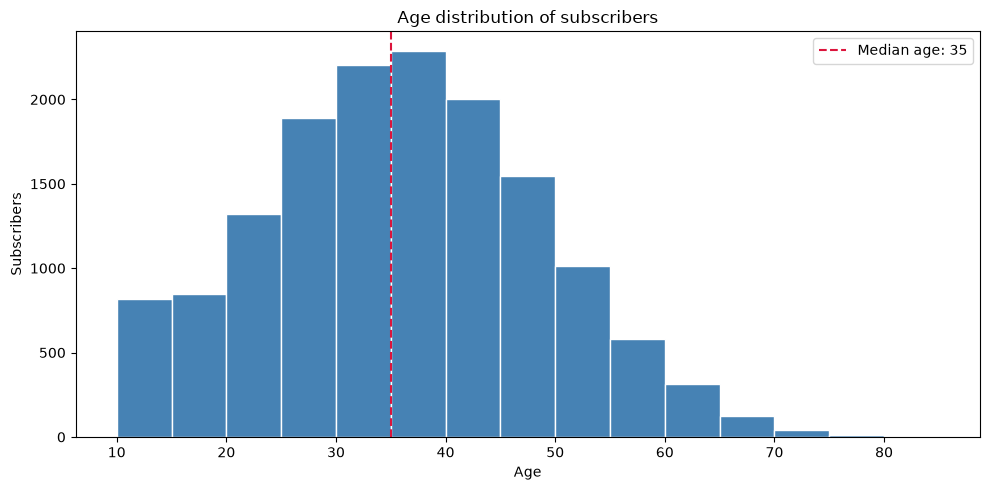

In [57]:
print(subscribers["age"].describe().round(1))  

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(subscribers["age"], bins=range(10, 90, 5), color="steelblue", edgecolor="white")
ax.axvline(subscribers["age"].median(), color="crimson", linestyle="--", label="Median age: 35")
ax.set_title("Age distribution of subscribers")
ax.set_xlabel("Age"); ax.set_ylabel("Subscribers")
ax.legend()
plt.tight_layout()
plt.savefig("charts/08_age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### --- Which age group watches most? ---

In [58]:
bins   = [12, 17, 24, 34, 44, 54, 64, 100]
labels = ["13-17", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
subscribers["age_group"] = pd.cut(subscribers["age"], bins, labels=labels)

hours_by_sub = sessions.groupby("subscriber_id")["hours"].sum()
subscribers["total_hours"] = subscribers["subscriber_id"].map(hours_by_sub).fillna(0)

age_tbl = subscribers.groupby("age_group", observed=True).agg(
    subscribers=("age", "size"),
    total_hours=("total_hours", "sum"),
    avg_hours=("total_hours", "mean")).round(1)
age_tbl["hours_share_%"] = (age_tbl["total_hours"] / age_tbl["total_hours"].sum() * 100).round(1)
print(age_tbl)

           subscribers  total_hours  avg_hours  hours_share_%
age_group                                                    
13-17             1270     281924.2      222.0            8.5
18-24             1715     358172.0      208.8           10.7
25-34             4094     890783.3      217.6           26.7
35-44             4291     972656.5      226.7           29.2
45-54             2557     603302.3      235.9           18.1
55-64              892     192413.1      215.7            5.8
65+                181      34216.4      189.0            1.0


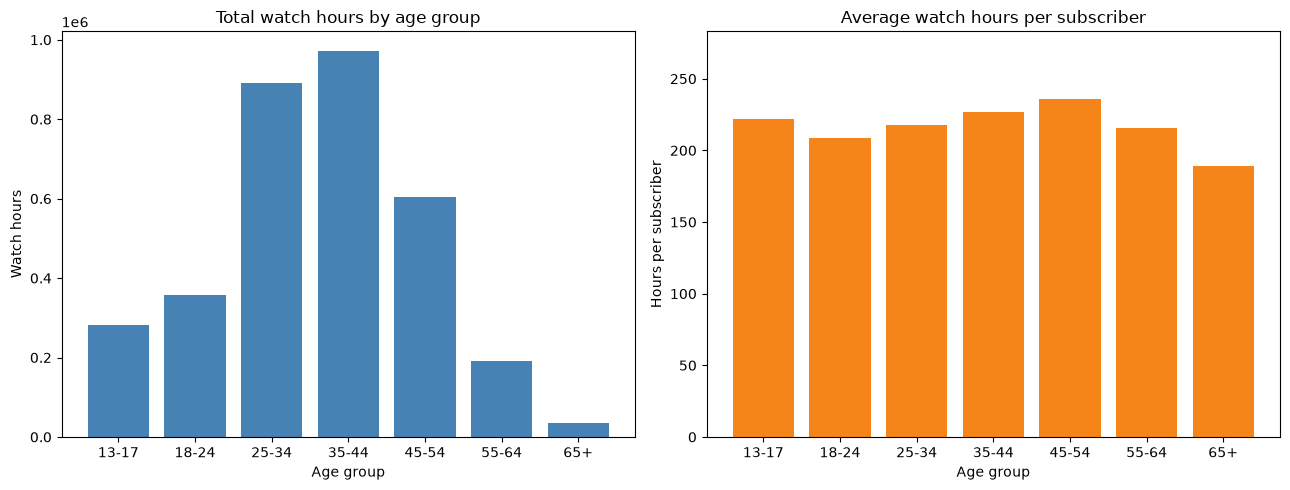

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(age_tbl.index, age_tbl["total_hours"], color="steelblue")
axes[0].set_title("Total watch hours by age group")
axes[0].set_xlabel("Age group"); axes[0].set_ylabel("Watch hours")
axes[1].bar(age_tbl.index, age_tbl["avg_hours"], color="#f58518")
axes[1].set_title("Average watch hours per subscriber")
axes[1].set_xlabel("Age group"); axes[1].set_ylabel("Hours per subscriber")
axes[1].set_ylim(0, age_tbl["avg_hours"].max() * 1.2)
plt.tight_layout()
plt.savefig("charts/08b_age_group_hours.png", dpi=150, bbox_inches="tight")
plt.show()

In [60]:
print(subscribers["age"].value_counts().sort_index().loc[13:17]) 

age
13    696
14    124
15    133
16    144
17    173
Name: count, dtype: int64


**Observation: Age distribution and viewing by age group**

Subscribers are concentrated between 25 and 45 (median age 35, mean 35.6), with a thinner tail up to 85. The 35-44 group watches the most in total (972,657 hours, 29% of all watch time), followed by 25-34 (27%), and together these two groups account for about 56% of viewing. This reflects group size, not stronger engagement: average hours per subscriber are similar in every group, from 189 (65+) to 236 (45-54), so the heaviest viewers per person are the 45-54 group, not the largest one.

*Note: 696 subscribers (4.6%) are recorded at exactly age 13, more than five times the count at age 14, which suggests ages were floored at 13; the 13-17 group (1,270 subscribers) should be read with this in mind.*

# Chart 9:	Completion rate by genre 

primary_genre
Musical          66.8
Animation        66.4
Stand-Up         66.3
Fantasy          66.0
Sci-Fi           65.8
Mystery          65.6
Crime            65.5
Thriller         65.3
Kids & Family    65.3
Horror           65.3
Comedy           65.3
Drama            65.1
Documentary      65.1
Romance          65.0
Action           64.8
Reality          64.7
Name: completion_pct, dtype: float64
65.3 0.153


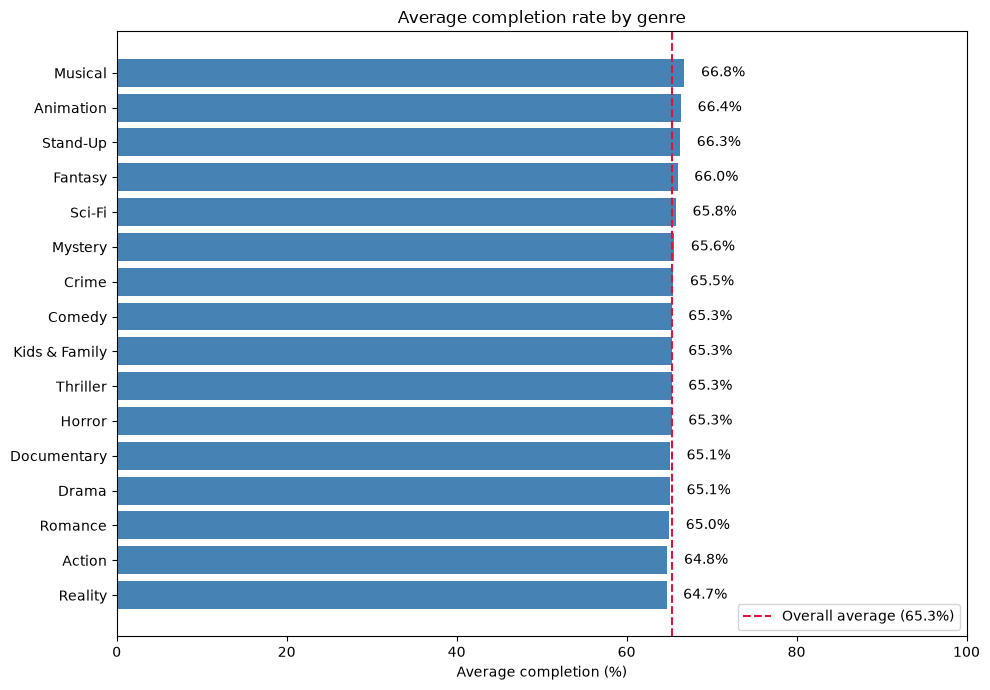

In [61]:
comp = sessions.groupby("primary_genre")["completion_pct"].mean().sort_values(ascending=True).round(1)
print(comp.sort_values(ascending=False))    
print(round(sessions["completion_pct"].mean(), 1), round(sessions["completed"].mean(), 3)) 

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(comp.index, comp.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v}%" for v in comp.values], padding=12,
             bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axvline(sessions["completion_pct"].mean(), color="crimson", linestyle="--", label="Overall average (65.3%)")
ax.set_xlim(0, 100)
ax.set_title("Average completion rate by genre")
ax.set_xlabel("Average completion (%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("charts/09_completion_by_genre.png", dpi=150, bbox_inches="tight")
plt.show()

In [62]:
print(sessions["primary_genre"].value_counts().tail(3))      

primary_genre
Mystery     18074
Stand-Up     7993
Musical      7425
Name: count, dtype: int64


In [63]:
g = sessions.groupby("primary_genre")["completion_pct"].agg(["mean", "std", "count"]).round(2)
print(g.sort_values("mean", ascending=False))

                mean    std  count
primary_genre                     
Musical        66.83  22.20   7425
Animation      66.38  22.45  29208
Stand-Up       66.32  22.63   7993
Fantasy        65.97  22.54  26407
Sci-Fi         65.79  22.53  33157
Mystery        65.56  22.45  18074
Crime          65.46  22.51  44153
Comedy         65.32  22.60  84455
Thriller       65.31  22.55  58589
Kids & Family  65.31  22.50  18338
Horror         65.26  22.65  28122
Documentary    65.13  22.54  57786
Drama          65.10  22.66  95624
Romance        65.00  22.77  44210
Action         64.81  22.74  77300
Reality        64.70  22.76  19159


**Observation: Completion rate by genre**

Completion is almost identical across genres: the average ranges only from 64.7% (Reality) to 66.8% (Musical), against an overall average of 65.3%. Even the smallest genres have over 7,000 sessions, so the ordering is not noise, but a gap of about two points is small next to the wide spread within every genre (individual sessions range from 1% to 100%), so genre says very little about whether a viewer finishes a title. Viewing typically stops well before the end: only about 15% of sessions reach the 90% mark used for the completed flag.

# Chart 10:	Review sentiment breakdown 

sentiment
Positive    74899
Neutral     22711
Negative    12219
Name: count, dtype: int64
sentiment
Positive    68.2
Neutral     20.7
Negative    11.1
Name: count, dtype: float64


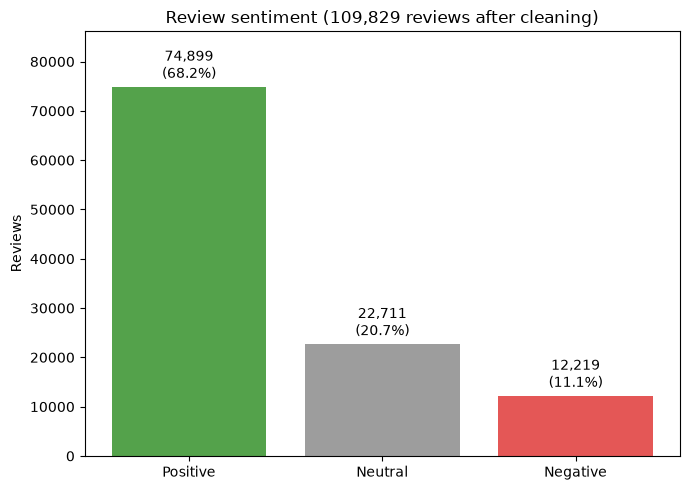

In [64]:
sent = reviews["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])
print(sent)                         
print((sent / sent.sum() * 100).round(1))     

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(sent.index, sent.values, color=["#54a24b", "#9d9d9d", "#e45756"])
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(sent.values, (sent / sent.sum() * 100).round(1))], padding=3)
ax.set_ylim(0, sent.max() * 1.15)
ax.set_title("Review sentiment (109,829 reviews after cleaning)")
ax.set_ylabel("Reviews")
plt.tight_layout()
plt.savefig("charts/10_review_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

### Average helpful votes by sentiment

In [65]:
print(reviews.groupby("sentiment")["helpful_votes"].mean().round(2))

sentiment
Negative    4.00
Neutral     4.01
Positive    9.00
Name: helpful_votes, dtype: float64


**Observation: Review sentiment**

Reviews are strongly positive: 74,899 of the 109,829 reviews (68.2%) are Positive, against 22,711 Neutral (20.7%) and 12,219 Negative (11.1%), so there are about six positive reviews for every negative one. Positive reviews also attract more than twice the helpful votes of the others (an average of 9.0, against 4.0 for both Neutral and Negative).

In [66]:
import os
files = sorted(os.listdir("charts"))
print(len(files)); print(files)

13
['01_monthly_sessions.png', '01b_monthly_sessions_log.png', '02_monthly_hours_yoy.png', '03_genre_share.png', '04_content_type_split.png', '05_top_countries.png', '06_plan_distribution.png', '07_device_usage.png', '08_age_distribution.png', '08b_age_group_hours.png', '09_completion_by_genre.png', '10_review_sentiment.png', 'bonus_cohort_retention.png']
